In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Montar o Google Drive (caso ainda não esteja montado)
from google.colab import drive
drive.mount('/content/drive')

# Configuração visual padrão acadêmico
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})

# 2. Caminhos reais no Google Drive conforme a estrutura do seu projeto
PASTA_RESULTADOS = "/content/drive/MyDrive/Segmentação_LCA/Resultados"
PASTA_GRAFICOS = os.path.join(PASTA_RESULTADOS, "Graficos_TCC")
os.makedirs(PASTA_GRAFICOS, exist_ok=True)

# Mapeamento exato das pastas criadas pelo seu código de treinamento
CENARIOS = {
    "unet_zero_orig": "U-Net Zero (Original)",
    "unet_zero_aug":  "U-Net Zero (Com Augmentation)",
    "unet_pre_orig":  "U-Net Pré-treinada (Original)",
    "unet_pre_aug":   "U-Net Pré-treinada (Com Augmentation)"
}

CORES_CENARIOS = {
    "unet_zero_orig": "#1f77b4",
    "unet_zero_aug":  "#ff7f0e",
    "unet_pre_orig":  "#2ca02c",
    "unet_pre_aug":   "#d62728"
}

# 3. Carregamento seguro dos dados dos 4 cenários
historicos = {}
resumos_teste = []

for pasta_cenario, nome_legivel in CENARIOS.items():
    caminho_cenario = os.path.join(PASTA_RESULTADOS, pasta_cenario)
    if not os.path.exists(caminho_cenario):
        print(f"Aviso: A pasta do cenário '{pasta_cenario}' ainda não foi encontrada em {caminho_cenario}. Rode o treino dela primeiro!")
        continue

    # Carrega os históricos dos 5 folds
    folds_dados = []
    for f in range(1, 6):
        arq_hist = os.path.join(caminho_cenario, f"historico_fold_{f}.csv")
        if os.path.exists(arq_hist):
            df_h = pd.read_csv(arq_hist)
            df_h["fold"] = f
            folds_dados.append(df_h)

    if folds_dados:
        historicos[pasta_cenario] = pd.concat(folds_dados, ignore_index=True)

    # Carrega o resumo do conjunto de teste fixo
    arq_teste = os.path.join(caminho_cenario, "resumo_teste.csv")
    if os.path.exists(arq_teste):
        df_t = pd.read_csv(arq_teste)
        # Padroniza as colunas de métricas de teste comuns
        cols_comuns = [c for c in ["fold", "dice_teste", "iou_teste"] if c in df_t.columns]
        df_t = df_t[cols_comuns].copy()
        df_t["cenario_id"] = pasta_cenario
        df_t["Cenario"] = nome_legivel
        resumos_teste.append(df_t)

if resumos_teste:
    df_teste_geral = pd.concat(resumos_teste, ignore_index=True)
else:
    df_teste_geral = pd.DataFrame()
    print("Aviso: Nenhum arquivo resumo_teste.csv foi encontrado ainda.")

print("Dados carregados com sucesso!")

Mounted at /content/drive
Dados carregados com sucesso!


In [3]:
import os
# Garante que a pasta de gráficos existe antes de salvar
os.makedirs(PASTA_GRAFICOS, exist_ok=True)

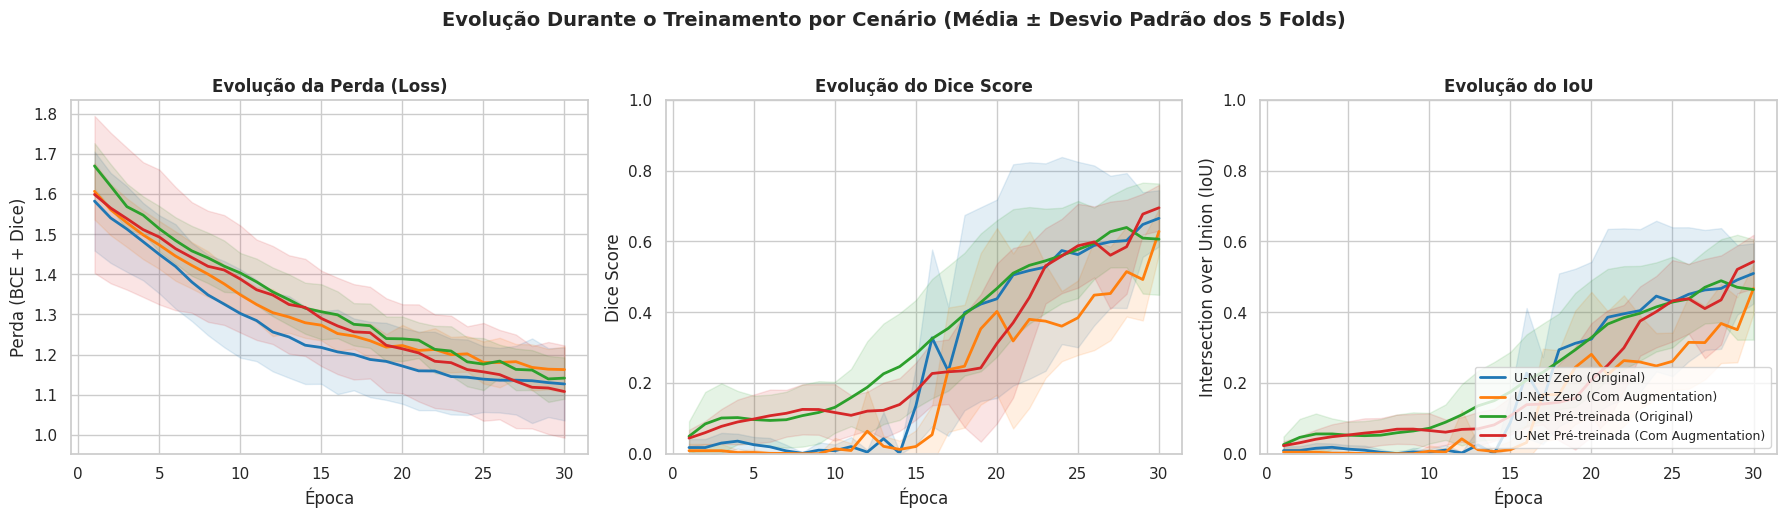

In [4]:
# Gráfico 1: Evolução por Época (Média ± Desvio Padrão dos 5 Folds)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
metricas_hist = [
    ("perda", "Evolução da Perda (Loss)", "Perda (BCE + Dice)"),
    ("dice",  "Evolução do Dice Score",   "Dice Score"),
    ("iou",   "Evolução do IoU",          "Intersection over Union (IoU)")
]

for ax, (col, titulo, ylabel) in zip(axes, metricas_hist):
    for cenario_id, nome_legivel in CENARIOS.items():
        if cenario_id not in historicos:
            continue
        df_c = historicos[cenario_id]
        stats = df_c.groupby("epoca")[col].agg(["mean", "std"]).reset_index()

        cor = CORES_CENARIOS[cenario_id]
        ax.plot(stats["epoca"], stats["mean"], label=nome_legivel, color=cor, linewidth=2)
        ax.fill_between(
            stats["epoca"],
            stats["mean"] - stats["std"],
            stats["mean"] + stats["std"],
            color=cor,
            alpha=0.12
        )
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.set_ylabel(ylabel)
    if col in ["dice", "iou"]:
        ax.set_ylim(0, 1.0)

axes[2].legend(loc="lower right", frameon=True, fontsize=9)
plt.suptitle("Evolução Durante o Treinamento por Cenário (Média ± Desvio Padrão dos 5 Folds)", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(os.path.join(PASTA_GRAFICOS, "01_evolucao_epocas_cenarios.png"), dpi=300, bbox_inches="tight")
plt.show()

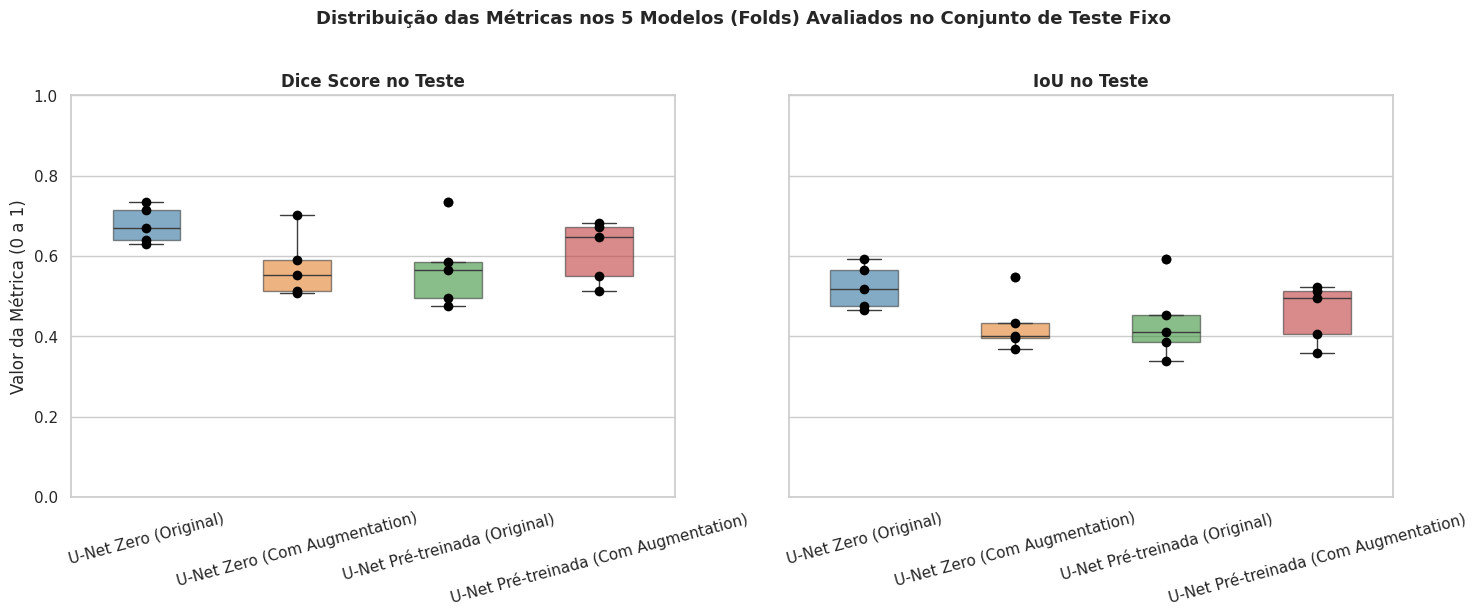

In [5]:
# Gráfico 3: Desempenho no Conjunto de Teste Fixo entre os 4 Cenários
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

for ax, (col_metrica, titulo_m) in zip(axes, [("dice_teste", "Dice Score no Teste"), ("iou_teste", "IoU no Teste")]):
    sns.boxplot(
        data=df_teste_geral,
        x="Cenario",
        y=col_metrica,
        hue="Cenario",
        palette=list(CORES_CENARIOS.values()),
        width=0.45,
        legend=False,
        ax=ax,
        boxprops=dict(alpha=0.6)
    )
    sns.stripplot(
        data=df_teste_geral,
        x="Cenario",
        y=col_metrica,
        color="black",
        size=7,
        jitter=False,
        ax=ax
    )
    ax.set_title(titulo_m)
    ax.set_xlabel("")
    ax.set_ylabel("Valor da Métrica (0 a 1)")
    ax.set_ylim(0, 1.0)
    ax.tick_params(axis="x", rotation=15)

plt.suptitle("Distribuição das Métricas nos 5 Modelos (Folds) Avaliados no Conjunto de Teste Fixo", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(PASTA_GRAFICOS, "03_comparacao_cenarios_teste_boxplot.png"), dpi=300, bbox_inches="tight")
plt.show()

In [6]:
# Tabela Resumo Numérica
resumo_numerico = df_teste_geral.groupby("Cenario", sort=False).agg(
    Dice_Media=("dice_teste", "mean"),
    Dice_DP=("dice_teste", "std"),
    IoU_Media=("iou_teste", "mean"),
    IoU_DP=("iou_teste", "std")
).reset_index()

print("\n=== TABELA CONSOLIDADA NO CONJUNTO DE TESTE (MÉDIA ± DESVIO PADRÃO DOS 5 FOLDS) ===")
print(resumo_numerico.to_string(index=False, float_format="%.4f"))
print(f"\nTodos os gráficos foram salvos automaticamente em alta resolução em: {PASTA_GRAFICOS}")


=== TABELA CONSOLIDADA NO CONJUNTO DE TESTE (MÉDIA ± DESVIO PADRÃO DOS 5 FOLDS) ===
                              Cenario  Dice_Media  Dice_DP  IoU_Media  IoU_DP
                U-Net Zero (Original)      0.6775   0.0462     0.5229  0.0556
        U-Net Zero (Com Augmentation)      0.5726   0.0799     0.4291  0.0702
        U-Net Pré-treinada (Original)      0.5710   0.1024     0.4356  0.0967
U-Net Pré-treinada (Com Augmentation)      0.6124   0.0763     0.4592  0.0726

Todos os gráficos foram salvos automaticamente em alta resolução em: /content/drive/MyDrive/Segmentação_LCA/Resultados/Graficos_TCC
